# Agriculture Crop Yield & Weather Impact Analysis

**Student:** Peeyush Chaudhary  |  **Admission No.:** 2026B01010687
**Course:** Python, NumPy & Pandas Individual Industry Projects (Five-Day Engineering Student Training, First Year – First Semester)
**Dataset:** `16_crop_yield.csv` (synthetic teaching dataset)

**Business scenario:** Examine regional crop production, rainfall, fertilizer usage and soil types to identify factors *associated with* higher agricultural yields.

> **Important note on interpretation:** the data is synthetic and observational. Every correlation or group difference reported below is an **association**, not proof of cause and effect.

**Notebook map (task numbers follow the assignment sheet):**
1. Load & inspect → 2. Missing values & duplicates → 3. Handle missing Rainfall/pH → 4. Yield per hectare → 5. Totals & average → 6. Crop ranking → 7. Regions → 8. Soil types → 9. Irrigated vs rain-fed → 10. Correlations → 11. Crop × Season → 12. NumPy statistics → 13. IQR outliers → 14. Rainfall categories → 15. Observations & recommendations

## 0. Setup: imports and configuration

In [5]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# ---- Locate the dataset (works from /src or from the repo root) ----
DATA_PATH = next((p for p in [Path("../data/16_crop_yield.csv"), Path("data/16_crop_yield.csv")] if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("16_crop_yield.csv not found in /data. Run data/generate_dataset.py first.")
print("Dataset file:", DATA_PATH.name)

# ---- Output folders ----
OUT_DIR = Path("../outputs") if Path("../data").exists() else Path("outputs")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- Column names used by the assignment sheet ----
ID, CROP, SEASON, SOIL = "Farm_Record_ID", "Crop_Type", "Season", "Soil_Type"
RAIN, PH, FERT = "Rainfall_mm", "Soil_pH", "Fertilizer_kg_per_ha"
AREA, PROD = "Area_Hectares", "Production_Tons"

ModuleNotFoundError: No module named 'matplotlib'

## 1. Load and inspect the dataset
**Task 1.** Load the CSV and look at its structure, data types and basic statistics.

In [ ]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df_raw.shape)
df_raw.head(10)

Shape (rows, columns): (612, 11)


,Farm_Record_ID,Region,Crop_Type,Season,Soil_Type,Irrigation_Type,Rainfall_mm,Soil_pH,Fertilizer_kg_per_ha,Area_Hectares,Production_Tons
0,FR0293,North,Mustard,Rabi,Clay,Irrigated,584.800,6.250,90.600,15.470,29.040
1,FR0516,East,Rice,Kharif,Clay,Rain-fed,984.700,6.320,158.300,23.150,102.860
2,FR0405,West,Maize,Kharif,Silty,Rain-fed,"1,114.800",5.700,140.300,6.040,31.960
3,FR0329,Central,Rice,Zaid,Silty,Irrigated,445.100,7.770,106.000,16.920,63.630
4,FR0218,East,Rice,Kharif,Silty,Irrigated,720.500,6.550,146.500,21.800,116.340
5,FR0054,South,Maize,Kharif,Loamy,Rain-fed,912.200,6.880,62.100,24.620,141.610
6,FR0559,North,Soybean,Kharif,Silty,Irrigated,558.200,6.050,114.300,16.400,52.180
7,FR0194,Central,Maize,Kharif,Silty,Rain-fed,984.100,7.580,61.600,8.020,46.390
8,FR0593,South,Wheat,Rabi,Clay,Rain-fed,"1,087.800",7.070,86.700,4.050,14.530
9,FR0408,West,Rice,Kharif,Clay,Irrigated,712.400,6.850,77.500,24.030,100.400


In [ ]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Farm_Record_ID        612 non-null    str    
 1   Region                612 non-null    str    
 2   Crop_Type             612 non-null    str    
 3   Season                612 non-null    str    
 4   Soil_Type             612 non-null    str    
 5   Irrigation_Type       612 non-null    str    
 6   Rainfall_mm           587 non-null    float64
 7   Soil_pH               591 non-null    float64
 8   Fertilizer_kg_per_ha  612 non-null    float64
 9   Area_Hectares         612 non-null    float64
 10  Production_Tons       612 non-null    float64
dtypes: float64(5), str(6)
memory usage: 52.7 KB


In [ ]:
print("Numeric summary:")
display(df_raw.describe())
print("Categorical summary:")
display(df_raw.describe(include="object"))

Numeric summary:


,Rainfall_mm,Soil_pH,Fertilizer_kg_per_ha,Area_Hectares,Production_Tons
count,587.000,591.000,612.000,612.000,612.000
mean,790.872,6.797,112.069,12.859,45.631
std,223.095,0.688,39.363,7.052,33.775
min,200.000,4.970,10.000,0.000,1.210
25%,639.600,6.320,84.000,6.967,20.020
50%,790.100,6.770,110.900,13.015,39.050
75%,941.800,7.205,140.025,19.040,63.685
max,"1,398.800",9.000,232.400,24.980,286.016


Categorical summary:


/tmp/ipykernel_96/3554953612.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df_raw.describe(include="object"))


,Farm_Record_ID,Region,Crop_Type,Season,Soil_Type,Irrigation_Type
count,612,612,612,612,612,612
unique,600,5,6,3,4,2
top,FR0405,Central,Soybean,Kharif,Clay,Irrigated
freq,2,131,110,388,171,344


**Detecting the region and irrigation columns.** The assignment sheet refers to "regions or districts" and
"irrigated versus rain-fed" without giving exact column names, so the code finds them automatically
(first match of Region / District / State, and any column whose name contains *irrig*). If your CSV uses other names, change them here.

In [ ]:
REGION = next((c for c in ["Region", "District", "State"] if c in df_raw.columns), None)
IRRIG = next((c for c in df_raw.columns if "irrig" in c.lower()), None)

required = [ID, CROP, SEASON, SOIL, RAIN, PH, FERT, AREA, PROD]
missing_cols = [c for c in required if c not in df_raw.columns]
assert not missing_cols, f"Columns not found in CSV: {missing_cols}"
assert REGION is not None, "No Region/District column found - set REGION manually."
assert IRRIG is not None, "No irrigation column found - set IRRIG manually."
print(f"Region column     : {REGION}")
print(f"Irrigation column : {IRRIG}")

Region column     : Region
Irrigation column : Irrigation_Type


## 2. Missing values and duplicate `Farm_Record_ID` rows
**Task 2.** Count missing values per column and find duplicated IDs.

In [ ]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_percent": (df_raw.isna().mean() * 100).round(2),
})
print("Missing values per column:")
display(missing[missing["missing_count"] > 0] if missing["missing_count"].any() else missing)

Missing values per column:


,missing_count,missing_percent
Rainfall_mm,25,4.080
Soil_pH,21,3.430


In [ ]:
dup_mask = df_raw.duplicated(subset=ID, keep=False)          # every row involved in a duplicate ID
n_dup_extra = df_raw.duplicated(subset=ID, keep="first").sum()  # surplus copies
n_exact = df_raw.duplicated(keep="first").sum()               # fully identical rows

print(f"Rows sharing a Farm_Record_ID with another row : {dup_mask.sum()}")
print(f"Surplus duplicate rows (would be removed)      : {n_dup_extra}")
print(f"  of which identical in every column           : {n_exact}")
print(f"Unique Farm_Record_IDs                         : {df_raw[ID].nunique()}")
df_raw[dup_mask].sort_values(ID).head(10)

Rows sharing a Farm_Record_ID with another row : 24
Surplus duplicate rows (would be removed)      : 12
  of which identical in every column           : 12
Unique Farm_Record_IDs                         : 600


,Farm_Record_ID,Region,Crop_Type,Season,Soil_Type,Irrigation_Type,Rainfall_mm,Soil_pH,Fertilizer_kg_per_ha,Area_Hectares,Production_Tons
416,FR0024,South,Mustard,Rabi,Silty,Rain-fed,822.500,7.750,95.200,13.320,24.530
115,FR0024,South,Mustard,Rabi,Silty,Rain-fed,822.500,7.750,95.200,13.320,24.530
483,FR0067,East,Mustard,Rabi,Sandy,Irrigated,617.600,6.510,143.000,8.750,15.870
179,FR0067,East,Mustard,Rabi,Sandy,Irrigated,617.600,6.510,143.000,8.750,15.870
257,FR0166,South,Soybean,Kharif,Sandy,Rain-fed,732.900,7.080,171.200,8.590,21.470
495,FR0166,South,Soybean,Kharif,Sandy,Rain-fed,732.900,7.080,171.200,8.590,21.470
580,FR0202,Central,Mustard,Rabi,Silty,Irrigated,684.400,6.490,88.500,19.260,38.240
142,FR0202,Central,Mustard,Rabi,Silty,Irrigated,684.400,6.490,88.500,19.260,38.240
500,FR0330,West,Cotton,Kharif,Clay,Rain-fed,"1,006.100",7.650,132.900,11.260,27.670
34,FR0330,West,Cotton,Kharif,Clay,Rain-fed,"1,006.100",7.650,132.900,11.260,27.670


## 3. Cleaning and handling missing `Rainfall_mm` / `Soil_pH`
**Task 3.** Cleaning approach (documented decisions):

| Step | Decision | Reason |
|---|---|---|
| Text columns | strip spaces, standardise capitalisation | avoids "loamy" and "Loamy " being counted as different groups |
| Duplicate IDs | keep the **first** record, drop the rest | a farm record should appear once; otherwise totals are double-counted |
| Missing `Rainfall_mm` | fill with the **median rainfall of the same Region** (overall median if a region has no data) | rainfall is a regional weather feature; median is robust to extreme values |
| Missing `Soil_pH` | fill with the **median pH of the same Soil_Type** (overall median as fallback) | pH is a property of the soil |
| Missing `Area`/`Production` or `Area <= 0` | **excluded from yield calculations** (kept in the table) | yield cannot be computed, and imputing them would invent production |
| Imputation flags | add `Rainfall_imputed`, `Soil_pH_imputed` columns | keeps the analysis transparent |

In [ ]:
df = df_raw.copy()

# 3a. Standardise text columns
text_cols = [CROP, SEASON, SOIL, REGION, IRRIG]
for c in text_cols:
    df[c] = df[c].astype("string").str.strip().str.title()

def standardise_irrigation(value):
    """Map the many ways irrigation can be written to 'Irrigated' / 'Rain-Fed'."""
    if pd.isna(value):
        return pd.NA
    s = str(value).strip().lower().replace("_", "-").replace(" ", "-")
    if s in {"yes", "y", "true", "1", "irrigated"}:
        return "Irrigated"
    if s in {"no", "n", "false", "0", "rainfed", "rain-fed", "non-irrigated", "none"}:
        return "Rain-Fed"
    return str(value).strip().title()          # keep any other label unchanged

df[IRRIG] = df[IRRIG].map(standardise_irrigation)
print("Irrigation categories:", df[IRRIG].dropna().unique().tolist())

# 3b. Remove duplicate Farm_Record_IDs (keep first)
before = len(df)
df = df.drop_duplicates(subset=ID, keep="first").reset_index(drop=True)
print(f"Rows before: {before}  |  after removing duplicate IDs: {len(df)}  |  removed: {before - len(df)}")

Irrigation categories: ['Irrigated', 'Rain-Fed']
Rows before: 612  |  after removing duplicate IDs: 600  |  removed: 12


In [ ]:
# 3c. Impute Rainfall_mm and Soil_pH (group median, then overall median as fallback)
df["Rainfall_imputed"] = df[RAIN].isna()
df["Soil_pH_imputed"] = df[PH].isna()

df[RAIN] = df[RAIN].fillna(df.groupby(REGION)[RAIN].transform("median"))
df[RAIN] = df[RAIN].fillna(df[RAIN].median())

df[PH] = df[PH].fillna(df.groupby(SOIL)[PH].transform("median"))
df[PH] = df[PH].fillna(df[PH].median())

print("Rainfall values imputed :", int(df["Rainfall_imputed"].sum()))
print("Soil_pH values imputed  :", int(df["Soil_pH_imputed"].sum()))
print("Remaining missing in Rainfall_mm / Soil_pH:", int(df[[RAIN, PH]].isna().sum().sum()))

# Sanity check: pH must lie between 0 and 14
bad_ph = ((df[PH] < 0) | (df[PH] > 14)).sum()
print("Soil_pH values outside 0-14:", int(bad_ph))

Rainfall values imputed : 25
Soil_pH values imputed  : 20
Remaining missing in Rainfall_mm / Soil_pH: 0
Soil_pH values outside 0-14: 0


## 4. Yield per hectare for every record
**Task 4.** `Yield_per_Hectare = Production_Tons / Area_Hectares`.
Division by zero is avoided with `np.where(Area_Hectares > 0, ...)` (hint from the assignment).

In [ ]:
valid_area = df[AREA] > 0
print("Records with Area_Hectares <= 0 or missing (yield not computable):", int((~valid_area).sum()))

safe_area = df[AREA].where(valid_area, np.nan)           # NaN where area is not valid
df["Yield_per_Hectare"] = np.where(valid_area, df[PROD] / safe_area, np.nan)

# Analysis table = rows with a valid yield
data = df.dropna(subset=["Yield_per_Hectare"]).copy()
Y = "Yield_per_Hectare"
print("Records used in the analysis:", len(data))
data[[ID, CROP, AREA, PROD, Y]].head(8)

Records with Area_Hectares <= 0 or missing (yield not computable): 4
Records used in the analysis: 596


,Farm_Record_ID,Crop_Type,Area_Hectares,Production_Tons,Yield_per_Hectare
0,FR0293,Mustard,15.470,29.040,1.877
1,FR0516,Rice,23.150,102.860,4.443
2,FR0405,Maize,6.040,31.960,5.291
3,FR0329,Rice,16.920,63.630,3.761
4,FR0218,Rice,21.800,116.340,5.337
5,FR0054,Maize,24.620,141.610,5.752
6,FR0559,Soybean,16.400,52.180,3.182
7,FR0194,Maize,8.020,46.390,5.784


## 5. Total production and average yield per hectare
**Task 5.** Two averages are shown because they answer different questions:
* **Mean of record yields** – the average farm record (every record counts equally).
* **Weighted yield** = total production ÷ total area – the yield of the whole area as one big farm (bigger farms count more).

In [ ]:
total_production = data[PROD].sum()
total_area = data[AREA].sum()
mean_record_yield = data[Y].mean()
weighted_yield = total_production / total_area

print(f"Total production (tons)                 : {total_production:,.2f}")
print(f"Total area (hectares)                   : {total_area:,.2f}")
print(f"Average yield per hectare (record mean) : {mean_record_yield:,.3f} t/ha")
print(f"Overall yield (total prod / total area) : {weighted_yield:,.3f} t/ha")

Total production (tons)                 : 27,302.23
Total area (hectares)                   : 7,703.95
Average yield per hectare (record mean) : 3.509 t/ha
Overall yield (total prod / total area) : 3.544 t/ha


## 6. Rank crop types by average yield per hectare
**Task 6 – Deliverable: crop productivity ranking.**

In [ ]:
crop_rank = (data.groupby(CROP)
                 .agg(Records=(ID, "count"),
                      Avg_Yield_t_per_ha=(Y, "mean"),
                      Median_Yield_t_per_ha=(Y, "median"),
                      Total_Production_t=(PROD, "sum"))
                 .sort_values("Avg_Yield_t_per_ha", ascending=False))
crop_rank.insert(0, "Rank", range(1, len(crop_rank) + 1))
crop_rank.to_csv(OUT_DIR / "crop_productivity_ranking.csv")
crop_rank

,Rank,Records,Avg_Yield_t_per_ha,Median_Yield_t_per_ha,Total_Production_t
Crop_Type,,,,,
Maize,1,97,5.530,5.360,"6,610.174"
Rice,2,109,4.580,4.507,"7,042.656"
Wheat,3,96,3.892,3.910,"5,103.768"
Soybean,4,108,2.749,2.803,"3,616.996"
Cotton,5,92,2.163,2.157,"2,535.078"
Mustard,6,94,1.981,1.957,"2,393.558"


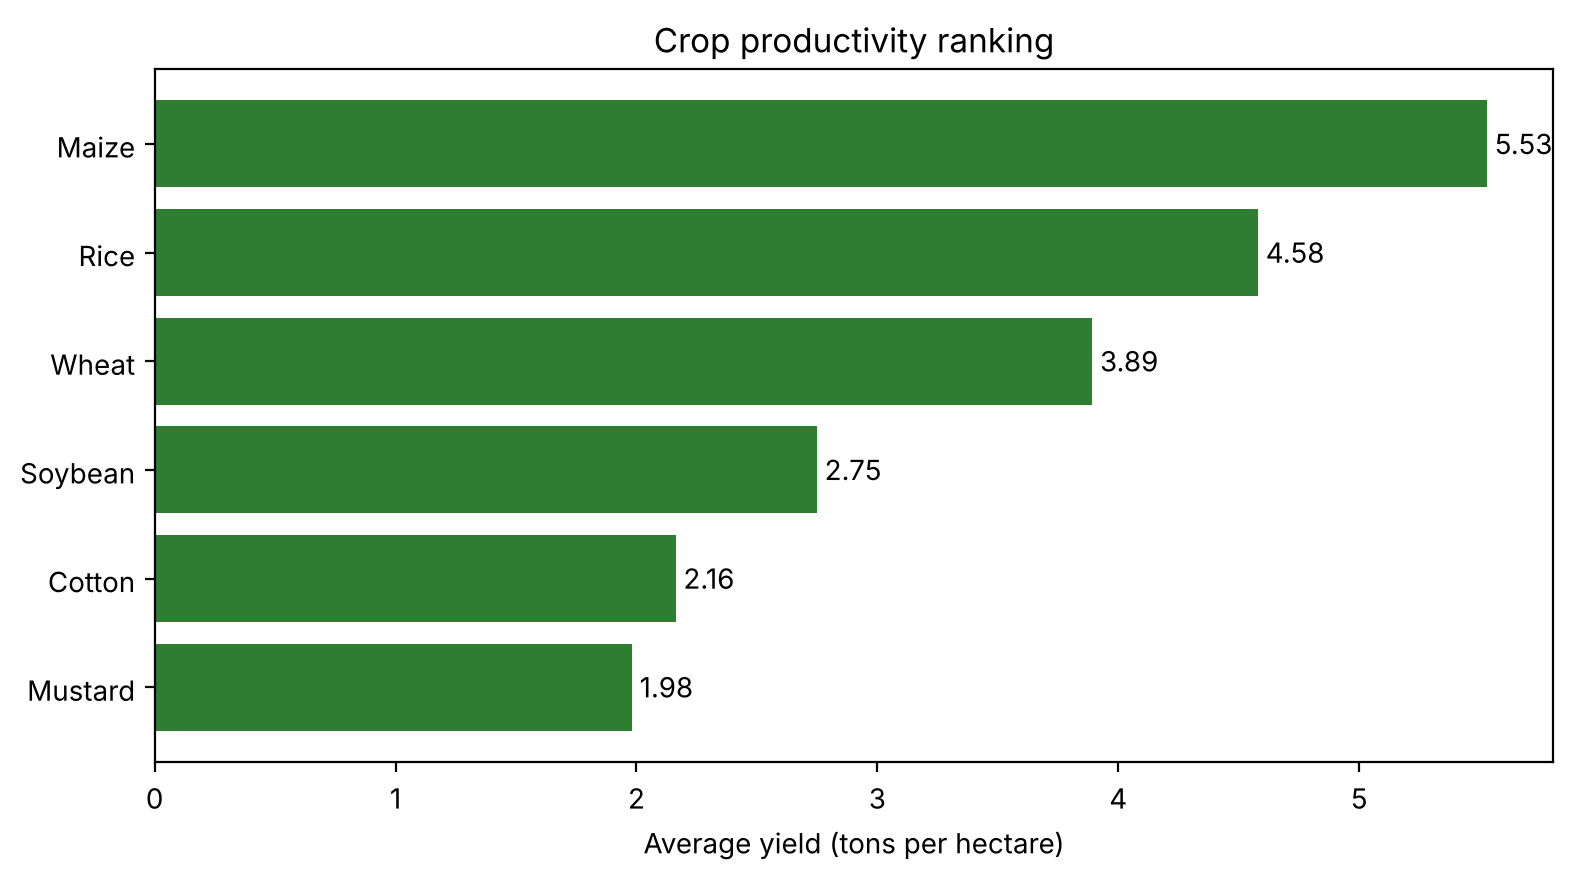

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(crop_rank.index[::-1], crop_rank["Avg_Yield_t_per_ha"][::-1], color="#2e7d32")
ax.set_xlabel("Average yield (tons per hectare)")
ax.set_title("Crop productivity ranking")
for i, v in enumerate(crop_rank["Avg_Yield_t_per_ha"][::-1]):
    ax.text(v, i, f" {v:.2f}", va="center")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_crop_ranking.png", dpi=150); plt.show()

## 7. Average crop yields across regions / districts
**Task 7.** First overall average yield per region, then crop-by-region table.

In [ ]:
region_yield = (data.groupby(REGION)
                    .agg(Records=(ID, "count"), Avg_Yield_t_per_ha=(Y, "mean"))
                    .sort_values("Avg_Yield_t_per_ha", ascending=False))
display(region_yield)

print("Average yield (t/ha) by Crop x Region:")
crop_region = data.pivot_table(index=CROP, columns=REGION, values=Y, aggfunc="mean")
display(crop_region)
crop_region.to_csv(OUT_DIR / "crop_by_region_yield.csv")

,Records,Avg_Yield_t_per_ha
Region,,
South,115,3.674
West,106,3.615
East,122,3.533
Central,130,3.466
North,123,3.284


Average yield (t/ha) by Crop x Region:


Region,Central,East,North,South,West
Crop_Type,,,,,
Cotton,2.161,2.204,2.023,2.153,2.379
Maize,5.597,5.481,5.637,5.757,5.016
Mustard,1.943,1.952,1.886,1.933,2.299
Rice,4.251,4.655,4.541,4.466,4.983
Soybean,2.637,2.891,2.614,2.817,2.760
Wheat,3.902,3.800,3.994,3.825,3.955


## 8. Average yield across soil types
**Task 8.**

In [ ]:
soil_yield = (data.groupby(SOIL)
                  .agg(Records=(ID, "count"), Avg_Yield_t_per_ha=(Y, "mean"),
                       Avg_Soil_pH=(PH, "mean"))
                  .sort_values("Avg_Yield_t_per_ha", ascending=False))
soil_yield.to_csv(OUT_DIR / "soil_type_yield.csv")
soil_yield

,Records,Avg_Yield_t_per_ha,Avg_Soil_pH
Soil_Type,,,
Loamy,150,3.869,6.700
Silty,143,3.611,6.847
Clay,167,3.471,6.793
Sandy,136,3.051,6.843


## 9. Irrigated versus rain-fed farms
**Task 9 – Deliverable: irrigation impact summary.**
Crops differ a lot in their natural yield, so a raw comparison can be misleading if one group grows more high-yield crops.
As an extra check, a **crop-adjusted yield index** is also shown: each record's yield divided by the average yield of its own crop (1.00 = typical for that crop).

In [ ]:
crop_mean = data.groupby(CROP)[Y].transform("mean")
data["Yield_Index_vs_Crop"] = data[Y] / crop_mean

irrig_summary = (data.groupby(IRRIG)
                     .agg(Records=(ID, "count"),
                          Avg_Yield_t_per_ha=(Y, "mean"),
                          Median_Yield_t_per_ha=(Y, "median"),
                          Crop_Adjusted_Index=("Yield_Index_vs_Crop", "mean"),
                          Avg_Fertilizer_kg_per_ha=(FERT, "mean"),
                          Avg_Rainfall_mm=(RAIN, "mean")))
irrig_summary.to_csv(OUT_DIR / "irrigation_impact_summary.csv")
display(irrig_summary)

if {"Irrigated", "Rain-Fed"} <= set(irrig_summary.index):
    gap = irrig_summary.loc["Irrigated", "Avg_Yield_t_per_ha"] - irrig_summary.loc["Rain-Fed", "Avg_Yield_t_per_ha"]
    pct = gap / irrig_summary.loc["Rain-Fed", "Avg_Yield_t_per_ha"] * 100
    print(f"Irrigated farms average {gap:+.3f} t/ha ({pct:+.1f}%) compared with rain-fed farms.")
    print("This is an association; irrigation access may go together with other advantages (soil, inputs, crop choice).")

# Irrigation effect within each crop
display(data.pivot_table(index=CROP, columns=IRRIG, values=Y, aggfunc="mean"))

,Records,Avg_Yield_t_per_ha,Median_Yield_t_per_ha,Crop_Adjusted_Index,Avg_Fertilizer_kg_per_ha,Avg_Rainfall_mm
Irrigation_Type,,,,,,
Irrigated,335,3.640,3.473,1.032,110.993,785.642
Rain-Fed,261,3.341,3.126,0.959,112.973,798.636


Irrigated farms average +0.299 t/ha (+8.9%) compared with rain-fed farms.
This is an association; irrigation access may go together with other advantages (soil, inputs, crop choice).


Irrigation_Type,Irrigated,Rain-Fed
Crop_Type,,
Cotton,2.243,2.058
Maize,5.725,5.264
Mustard,2.054,1.886
Rice,4.689,4.437
Soybean,2.863,2.626
Wheat,3.968,3.786


## 10. Correlations: Rainfall, Fertilizer and Yield
**Task 10.** Pearson correlation (linear association) with Spearman (rank-based) as a robustness check.
*Correlations here are associations in synthetic data and do not prove causation.*

In [ ]:
corr_cols = [RAIN, FERT, Y]
pearson = data[corr_cols].corr()
spearman = data[corr_cols].corr(method="spearman")
print("Pearson correlation:");  display(pearson)
print("Spearman correlation:"); display(spearman)

def strength(r):
    a = abs(r)
    word = "negligible" if a < 0.1 else "weak" if a < 0.3 else "moderate" if a < 0.5 else "strong"
    return f"{word} {'positive' if r > 0 else 'negative'}"

r_rain = pearson.loc[RAIN, Y]; r_fert = pearson.loc[FERT, Y]; r_rf = pearson.loc[RAIN, FERT]
print(f"Rainfall   vs Yield : r = {r_rain:+.3f} ({strength(r_rain)})")
print(f"Fertilizer vs Yield : r = {r_fert:+.3f} ({strength(r_fert)})")
print(f"Rainfall   vs Fertilizer : r = {r_rf:+.3f} ({strength(r_rf)})")

Pearson correlation:


,Rainfall_mm,Fertilizer_kg_per_ha,Yield_per_Hectare
Rainfall_mm,1.000,-0.052,0.179
Fertilizer_kg_per_ha,-0.052,1.000,0.056
Yield_per_Hectare,0.179,0.056,1.000


Spearman correlation:


,Rainfall_mm,Fertilizer_kg_per_ha,Yield_per_Hectare
Rainfall_mm,1.000,-0.055,0.188
Fertilizer_kg_per_ha,-0.055,1.000,0.067
Yield_per_Hectare,0.188,0.067,1.000


Rainfall   vs Yield : r = +0.179 (weak positive)
Fertilizer vs Yield : r = +0.056 (negligible positive)
Rainfall   vs Fertilizer : r = -0.052 (negligible negative)


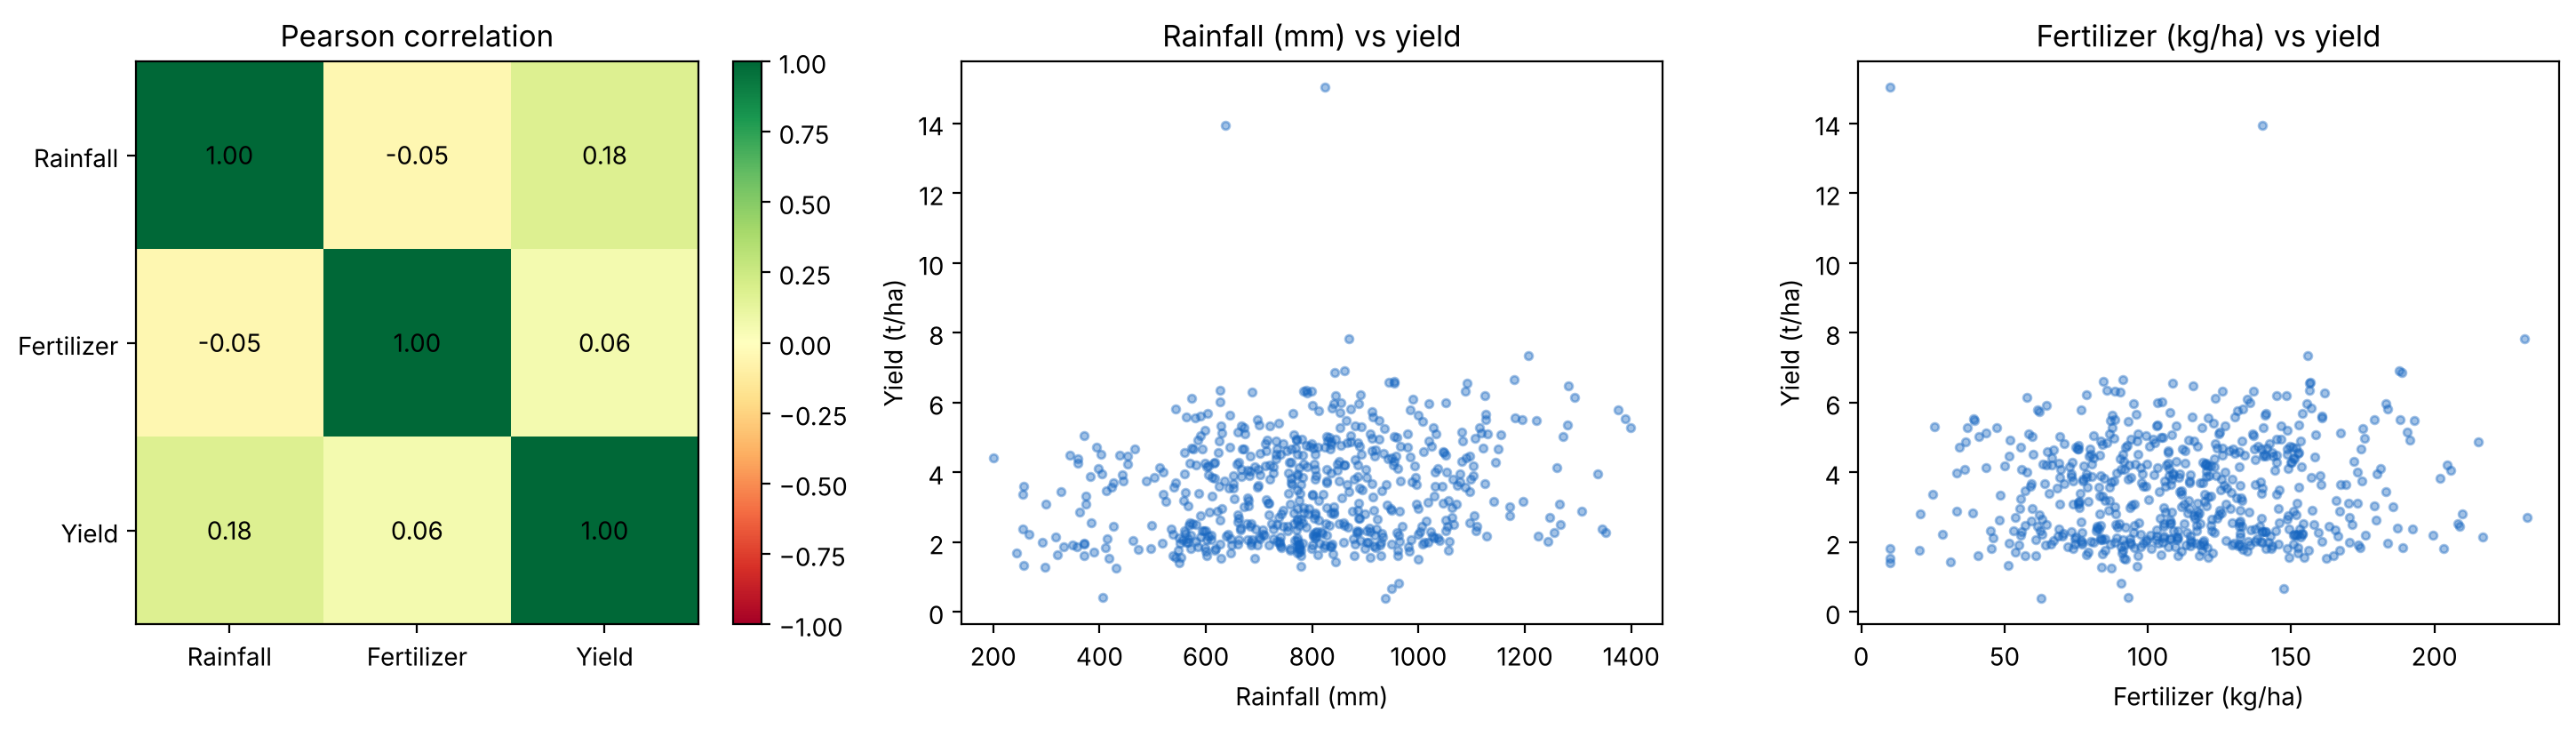

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
im = axes[0].imshow(pearson, cmap="RdYlGn", vmin=-1, vmax=1)
axes[0].set_xticks(range(3)); axes[0].set_yticks(range(3))
axes[0].set_xticklabels(["Rainfall", "Fertilizer", "Yield"]); axes[0].set_yticklabels(["Rainfall", "Fertilizer", "Yield"])
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{pearson.iloc[i, j]:.2f}", ha="center", va="center")
axes[0].set_title("Pearson correlation"); plt.colorbar(im, ax=axes[0], fraction=0.046)

for ax, col, name in [(axes[1], RAIN, "Rainfall (mm)"), (axes[2], FERT, "Fertilizer (kg/ha)")]:
    ax.scatter(data[col], data[Y], s=10, alpha=0.4, color="#1565c0")
    ax.set_xlabel(name); ax.set_ylabel("Yield (t/ha)"); ax.set_title(f"{name} vs yield")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_correlations.png", dpi=150); plt.show()

## 11. Group by Crop type and Season
**Task 11 – Deliverable: seasonal comparison table.**

In [ ]:
crop_season = (data.groupby([CROP, SEASON])
                   .agg(Records=(ID, "count"),
                        Avg_Yield_t_per_ha=(Y, "mean"),
                        Total_Production_t=(PROD, "sum"))
                   .reset_index())
crop_season.to_csv(OUT_DIR / "seasonal_comparison.csv", index=False)
display(crop_season)

print("Seasonal comparison table (average yield, t/ha):")
season_table = data.pivot_table(index=CROP, columns=SEASON, values=Y, aggfunc="mean")
display(season_table)

print("Average yield by season (all crops):")
display(data.groupby(SEASON)[Y].agg(["count", "mean"]).sort_values("mean", ascending=False))

,Crop_Type,Season,Records,Avg_Yield_t_per_ha,Total_Production_t
0,Cotton,Kharif,79,2.171,"2,238.098"
1,Cotton,Rabi,9,2.084,150.520
2,Cotton,Zaid,4,2.183,146.460
3,Maize,Kharif,89,5.536,"5,976.494"
4,Maize,Rabi,5,5.284,329.230
5,Maize,Zaid,3,5.778,304.450
6,Mustard,Kharif,7,1.863,170.130
7,Mustard,Rabi,85,1.991,"2,175.478"
8,Mustard,Zaid,2,1.956,47.950
9,Rice,Kharif,101,4.593,"6,479.236"


Seasonal comparison table (average yield, t/ha):


Season,Kharif,Rabi,Zaid
Crop_Type,,,
Cotton,2.171,2.084,2.183
Maize,5.536,5.284,5.778
Mustard,1.863,1.991,1.956
Rice,4.593,4.415,4.426
Soybean,2.754,2.867,2.618
Wheat,3.848,3.868,4.174


Average yield by season (all crops):


,count,mean
Season,,
Kharif,380,3.774
Zaid,26,3.483
Rabi,190,2.982


## 12. NumPy statistics of yield per hectare
**Task 12.** Median, variance and quartiles calculated with NumPy arrays.
Both sample variance (`ddof=1`, used when the data is a sample) and population variance (`ddof=0`) are shown.

In [ ]:
yield_arr = data[Y].to_numpy(dtype=float)

median_y = np.median(yield_arr)
var_sample = np.var(yield_arr, ddof=1)
var_pop = np.var(yield_arr, ddof=0)
std_sample = np.std(yield_arr, ddof=1)
q1, q2, q3 = np.percentile(yield_arr, [25, 50, 75])

stats_table = pd.Series({
    "Count": yield_arr.size, "Mean": yield_arr.mean(), "Median": median_y,
    "Variance (sample, ddof=1)": var_sample, "Variance (population, ddof=0)": var_pop,
    "Std deviation (sample)": std_sample, "Minimum": yield_arr.min(),
    "Q1 (25th percentile)": q1, "Q2 (50th percentile)": q2, "Q3 (75th percentile)": q3,
    "Maximum": yield_arr.max(),
}, name="Yield_per_Hectare")
stats_table

Count                           596.000
Mean                              3.509
Median                            3.368
Variance (sample, ddof=1)         2.297
Variance (population, ddof=0)     2.293
Std deviation (sample)            1.516
Minimum                           0.381
Q1 (25th percentile)              2.237
Q2 (50th percentile)              3.368
Q3 (75th percentile)              4.524
Maximum                          15.043
Name: Yield_per_Hectare, dtype: float64

## 13. Outliers using the IQR method
**Task 13 – Deliverable: outlier list.**
Rule: a value is an outlier if it is below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`.
Because crops naturally have very different yields, the same rule is also applied **within each crop** (an extra analysis) so that a normal high-yield crop is not mislabelled.

In [ ]:
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1 = {q1:.3f}, Q3 = {q3:.3f}, IQR = {iqr:.3f}")
print(f"Lower fence = {lower_fence:.3f}, Upper fence = {upper_fence:.3f}")

data["Outlier_Type"] = np.select(
    [data[Y] < lower_fence, data[Y] > upper_fence], ["Unusually Low", "Unusually High"], default="Normal")
outliers = (data[data["Outlier_Type"] != "Normal"]
            [[ID, CROP, REGION, SEASON, AREA, PROD, Y, "Outlier_Type"]]
            .sort_values(Y, ascending=False))
print(f"Overall outliers: {len(outliers)}  ({(outliers['Outlier_Type']=='Unusually High').sum()} high, "
      f"{(outliers['Outlier_Type']=='Unusually Low').sum()} low)")
outliers.to_csv(OUT_DIR / "outlier_list.csv", index=False)
display(outliers.head(20))

Q1 = 2.237, Q3 = 4.524, IQR = 2.287
Lower fence = -1.194, Upper fence = 7.955
Overall outliers: 2  (2 high, 0 low)


,Farm_Record_ID,Crop_Type,Region,Season,Area_Hectares,Production_Tons,Yield_per_Hectare,Outlier_Type
366,FR0252,Maize,South,Kharif,3.110,46.784,15.043,Unusually High
445,FR0117,Rice,West,Kharif,20.500,286.016,13.952,Unusually High


Outliers within crop: 13


,Farm_Record_ID,Crop_Type,Region,Yield_per_Hectare,Outlier_Within_Crop
413,FR0311,Cotton,North,0.414,Unusually Low
468,FR0366,Cotton,North,3.085,Unusually High
414,FR0255,Cotton,West,5.777,Unusually High
127,FR0440,Maize,Central,7.819,Unusually High
366,FR0252,Maize,South,15.043,Unusually High
372,FR0492,Mustard,East,0.381,Unusually Low
465,FR0594,Mustard,West,6.104,Unusually High
283,FR0575,Rice,West,6.209,Unusually High
445,FR0117,Rice,West,13.952,Unusually High
96,FR0391,Soybean,North,0.660,Unusually Low


/tmp/ipykernel_96/61297494.py:15: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(yield_arr, vert=False); axes[0].set_xlabel("Yield (t/ha)"); axes[0].set_title("Overall yield: boxplot")


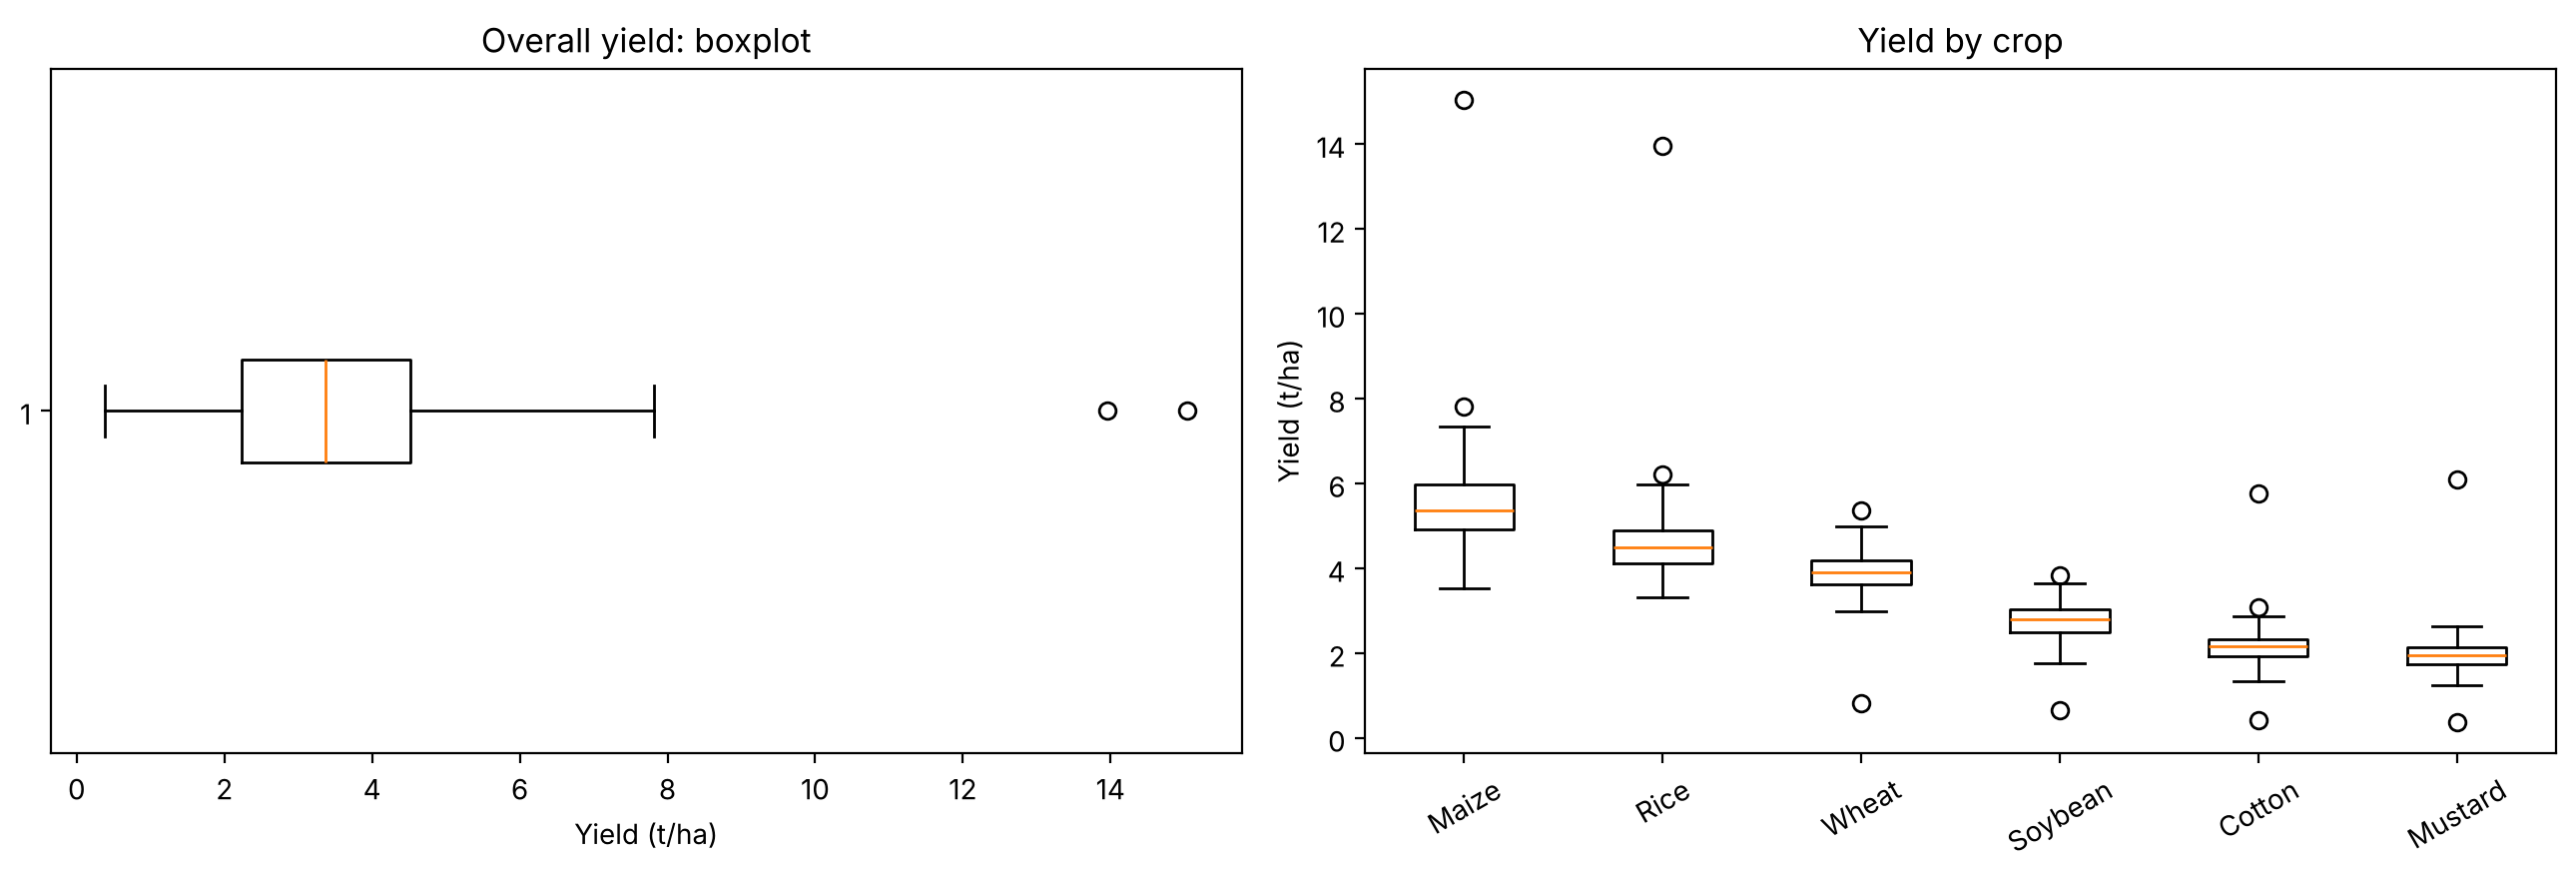

In [ ]:
# Extra: IQR applied separately inside each crop
def iqr_flags(s):
    a, b = s.quantile(0.25), s.quantile(0.75)
    k = b - a
    return pd.Series(np.select([s < a - 1.5 * k, s > b + 1.5 * k], ["Unusually Low", "Unusually High"], "Normal"),
                     index=s.index)

data["Outlier_Within_Crop"] = data.groupby(CROP, group_keys=False)[Y].apply(iqr_flags)
within = data[data["Outlier_Within_Crop"] != "Normal"][[ID, CROP, REGION, Y, "Outlier_Within_Crop"]]
print("Outliers within crop:", len(within))
within.sort_values([CROP, Y]).to_csv(OUT_DIR / "outlier_list_within_crop.csv", index=False)
display(within.sort_values([CROP, Y]).head(15))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].boxplot(yield_arr, vert=False); axes[0].set_xlabel("Yield (t/ha)"); axes[0].set_title("Overall yield: boxplot")
order = crop_rank.index.tolist()
axes[1].boxplot([data.loc[data[CROP] == c, Y] for c in order], tick_labels=order)
axes[1].set_ylabel("Yield (t/ha)"); axes[1].set_title("Yield by crop"); axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIG_DIR / "03_outliers_boxplots.png", dpi=150); plt.show()

## 14. Rainfall categories (Low / Moderate / High)
**Task 14.** Categories are created from the data with **tertiles** (`pd.qcut`): lowest third = Low, middle third = Moderate, highest third = High.
This avoids hard-coded thresholds, and each group has a similar number of records.

In [ ]:
data["Rainfall_Category"] = pd.qcut(data[RAIN], q=3, labels=["Low", "Moderate", "High"])

bounds = data.groupby("Rainfall_Category", observed=True)[RAIN].agg(["min", "max"])
print("Rainfall range of each category (mm):"); display(bounds)

rain_cat = (data.groupby("Rainfall_Category", observed=True)
                .agg(Records=(ID, "count"),
                     Avg_Yield_t_per_ha=(Y, "mean"),
                     Median_Yield_t_per_ha=(Y, "median"),
                     Crop_Adjusted_Index=("Yield_Index_vs_Crop", "mean")))
rain_cat.to_csv(OUT_DIR / "rainfall_category_yield.csv")
rain_cat

Rainfall range of each category (mm):


,min,max
Rainfall_Category,,
Low,200.000,702.000
Moderate,702.700,880.900
High,881.200,"1,398.800"


,Records,Avg_Yield_t_per_ha,Median_Yield_t_per_ha,Crop_Adjusted_Index
Rainfall_Category,,,,
Low,199,3.280,3.168,0.937
Moderate,198,3.556,3.310,1.009
High,199,3.691,3.653,1.054


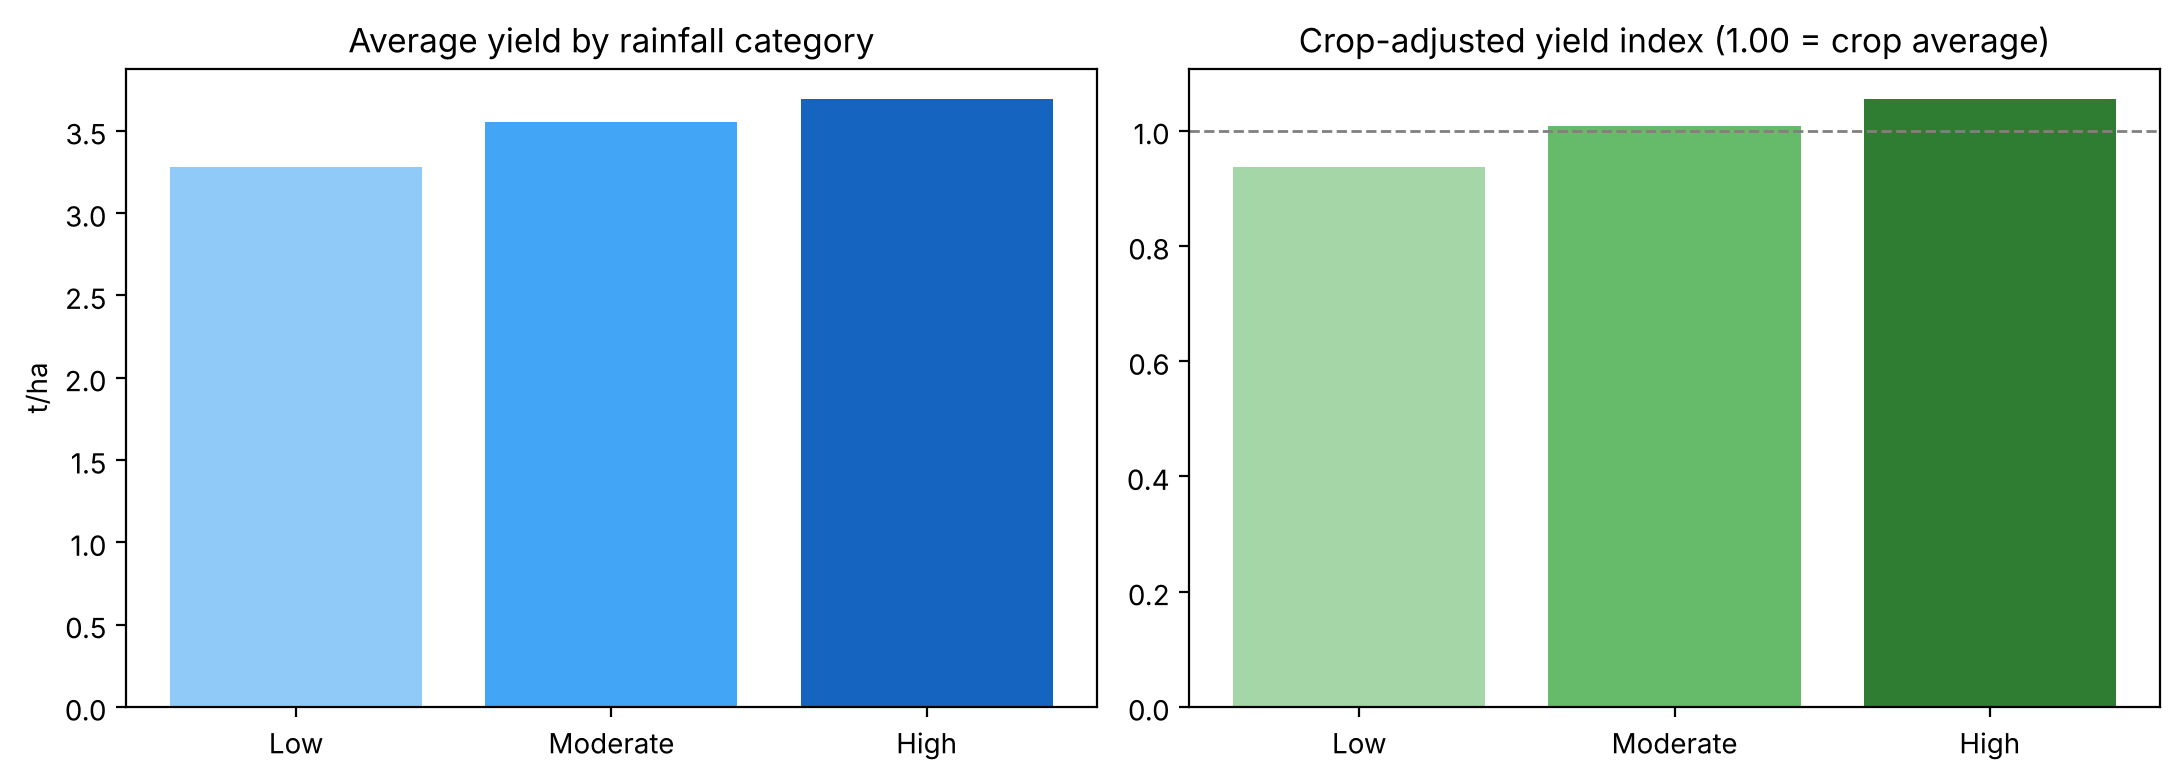

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(rain_cat.index.astype(str), rain_cat["Avg_Yield_t_per_ha"], color=["#90caf9", "#42a5f5", "#1565c0"])
ax[0].set_title("Average yield by rainfall category"); ax[0].set_ylabel("t/ha")
ax[1].bar(rain_cat.index.astype(str), rain_cat["Crop_Adjusted_Index"], color=["#a5d6a7", "#66bb6a", "#2e7d32"])
ax[1].axhline(1, color="grey", ls="--", lw=1); ax[1].set_title("Crop-adjusted yield index (1.00 = crop average)")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_rainfall_categories.png", dpi=150); plt.show()

## 15. Five cautious agronomic observations and recommendations
**Task 15.** The sentences below are **generated from the computed results** (no hard-coded numbers), so they always match the data.
Wording is deliberately cautious: "associated with", "may", "worth testing". None of them claims causation.

In [ ]:
best_crop, worst_crop = crop_rank.index[0], crop_rank.index[-1]
best_soil, worst_soil = soil_yield.index[0], soil_yield.index[-1]
best_season = data.groupby(SEASON)[Y].mean().idxmax()
best_region = region_yield.index[0]
dir_word = lambda r: "higher" if r > 0 else "lower"

# Irrigation sentence (adapts if the two expected labels are absent)
if {"Irrigated", "Rain-Fed"} <= set(irrig_summary.index):
    i_y = irrig_summary.loc["Irrigated", "Avg_Yield_t_per_ha"]; r_y = irrig_summary.loc["Rain-Fed", "Avg_Yield_t_per_ha"]
    i_x = irrig_summary.loc["Irrigated", "Crop_Adjusted_Index"]; r_x = irrig_summary.loc["Rain-Fed", "Crop_Adjusted_Index"]
    obs2 = (f"Irrigated records average {i_y:.2f} t/ha versus {r_y:.2f} t/ha for rain-fed records "
            f"({(i_y / r_y - 1) * 100:+.1f}%); after adjusting for crop type the index is {i_x:.2f} vs {r_x:.2f}. "
            f"Irrigation access is associated with {dir_word(i_y - r_y)} yields, but farms with irrigation may also differ in soil, inputs and management. "
            f"Recommendation: compare irrigated and rain-fed plots of the same crop and soil before investing.")
else:
    obs2 = "Irrigation groups could not be compared with the expected labels; review the irrigation column."

lowcat, highcat = rain_cat.index[0], rain_cat.index[-1]
obs = [
    (f"Crop type shows the largest differences: {best_crop} has the highest average yield ({crop_rank["Avg_Yield_t_per_ha"].iloc[0]:.2f} t/ha) and "
     f"{worst_crop} the lowest ({crop_rank["Avg_Yield_t_per_ha"].iloc[-1]:.2f} t/ha). Crops differ naturally in yield, so rankings should be read as descriptions of this dataset, "
     f"not as advice to switch crops. Recommendation: compare farms within the same crop, and judge profitability with price and cost data."),
    obs2,
    (f"Rainfall has a {strength(r_rain)} correlation with yield (r = {r_rain:+.2f}); {highcat}-rainfall records average "
     f"{rain_cat.loc[highcat, 'Avg_Yield_t_per_ha']:.2f} t/ha versus {rain_cat.loc[lowcat, 'Avg_Yield_t_per_ha']:.2f} t/ha for {lowcat}-rainfall records. "
     f"Timing and distribution of rain are not in the data, so total rainfall alone is an incomplete picture. "
     f"Recommendation: add seasonal rainfall distribution and drought/flood indicators in future data collection."),
    (f"Fertilizer use has a {strength(r_fert)} correlation with yield (r = {r_fert:+.2f}). A correlation cannot show the best dose or whether "
     f"returns diminish at high levels. Recommendation: use controlled field trials with several dose levels per crop before changing fertilizer plans, "
     f"and consider cost and environmental effects."),
    (f"{best_soil} soil has the highest average yield ({soil_yield["Avg_Yield_t_per_ha"].iloc[0]:.2f} t/ha) and {worst_soil} the lowest ({soil_yield["Avg_Yield_t_per_ha"].iloc[-1]:.2f} t/ha); "
     f"{best_season} is the most productive season on average and {best_region} the highest-yielding region. These patterns may reflect which crops are grown where. "
     f"The IQR method flagged {len(outliers)} unusual records overall ({len(within)} within crop). "
     f"Recommendation: verify those records for entry errors, then investigate genuine extremes (very high or very low) for management lessons."),
]
for k, text in enumerate(obs, 1):
    print(f"{k}. {text}\n")

(OUT_DIR / "recommendations.txt").write_text(
    "Agriculture Crop Yield & Weather Impact Analysis - Observations and Recommendations\n"
    "(Associations in synthetic data; no causal claims.)\n\n" + "\n\n".join(f"{k}. {t}" for k, t in enumerate(obs, 1)),
    encoding="utf-8")

1. Crop type shows the largest differences: Maize has the highest average yield (5.53 t/ha) and Mustard the lowest (1.98 t/ha). Crops differ naturally in yield, so rankings should be read as descriptions of this dataset, not as advice to switch crops. Recommendation: compare farms within the same crop, and judge profitability with price and cost data.

2. Irrigated records average 3.64 t/ha versus 3.34 t/ha for rain-fed records (+8.9%); after adjusting for crop type the index is 1.03 vs 0.96. Irrigation access is associated with higher yields, but farms with irrigation may also differ in soil, inputs and management. Recommendation: compare irrigated and rain-fed plots of the same crop and soil before investing.

3. Rainfall has a weak positive correlation with yield (r = +0.18); High-rainfall records average 3.69 t/ha versus 3.28 t/ha for Low-rainfall records. Timing and distribution of rain are not in the data, so total rainfall alone is an incomplete picture. Recommendation: add seas

1979

## 16. Assumptions and limitations
* The dataset is **synthetic**; real-world agronomy is more complex, so results are illustrative.
* All findings are **associations**. Observational data cannot establish that rainfall, fertilizer, soil or irrigation *cause* yield differences.
* Median imputation (by region for rainfall, by soil type for pH) reduces variation slightly and assumes the missing values are similar to their group.
* Duplicate IDs were resolved by keeping the first record; if duplicates differed, the choice may matter.
* Records with zero/missing area were excluded from yield calculations only.
* Crop type is a confounder for almost every comparison (crops have different natural yields), which is why crop-adjusted indices and within-crop checks were added.
* Rainfall categories are tertiles of this dataset, not agronomic thresholds.
* Weather timing, temperature, variety, pests and management practices are not in the data.

In [ ]:
print("Analysis complete. Output files saved in:", OUT_DIR.resolve())
print(sorted(p.name for p in OUT_DIR.glob("*.*")))

Analysis complete. Output files saved in: /home/claude/repo/outputs
['crop_by_region_yield.csv', 'crop_productivity_ranking.csv', 'irrigation_impact_summary.csv', 'outlier_list.csv', 'outlier_list_within_crop.csv', 'rainfall_category_yield.csv', 'recommendations.txt', 'seasonal_comparison.csv', 'soil_type_yield.csv']
